In [55]:
%matplotlib widget
import importlib
import numpy as np
import scipy
import pickle
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
#import pandas as pd
import time
from PIL import Image
import matplotlib.image

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## File name format

the format is "pmmdd_n_desc_SOU_xxxnm"

p : first letter is p

mm : month (06, 10...)

dd : day (15, 22...)

n : scan number of the day

desc : anything to describe the scan (map size, sample characteristics...)

SOU : laser source (SGH, OPO, CHA, Maitai...)

xxxnm : wavelength

## Get data

A main directory will contain experimental data and numerically treated maps. In that directory, there is a "Scan" directory containing the SMS maps.

In [56]:
# The path of the main directory
dir_root = r'H:\commun\Utilisateur FNO\Nathan\Experimental\test_diamter_dependence'

dir_data = dir_root + r'\Scan'

#cropping parameters for 1D fit : how many lines we remove on each sides.
dn_low = 2
dn_high = 2
dn_left = -1
dn_right = -1

#SMS acquisition parameters
V_lia = 0.414
c = 0.73

freq = 1500
coeff_sms = 2.28

Create a dictionnary with all maps

In [57]:
Data = create_dataset(dir_data, V_lia, c, freq, coeff_sms)

## Fit

### 1D fit

In [58]:
for key in Data :

    #get the SMS object
    sms = Data[key]
    
    #Cropping images
    sms.crop(dn_low = dn_low, dn_high=dn_high, dn_left=dn_left, dn_right=dn_right)    
    FWHM, amp_1D = sms.fit_FWHM_1D(line_fit)

### Find_peaks fit

In [59]:
for key in Data :
    sms = Data[key]
    sms.fit_peaks()
    

### 2D fit

Choosing the parameters we want to fit

In [60]:
#par_lists =           ['fwhm']
#par_lists =           ['dy', 'fwhm']
#par_lists =           ['x0', 'y0', 'fwhm']
#par_lists =           ['amp', 'fwhm']
par_lists =            ['x0', 'y0', 'amp', 'fwhm']
#par_lists =           ['x0', 'y0', 'dy', 'fwhm']
#par_lists =           ['x0', 'y0', 'fwhm']
#par_lists =           ['x0', 'y0', 'amp', 'dy']
#par_lists =           ['x0', 'y0', 'amp', 'dy', 'fwhm']

We create a fitting function which fitted parameters are only those of par_to_fit

In [61]:
def DTT_fit(XY,x0=sms.x[sms.i_max],y0=sms.y[sms.j_max], amp=sms.amp,dy=sms.c*sms.V_lia, fwhm=sms.FWHM_1D): #NA=0.7 pour le setup
    """SMS figure for the given parameters.

    Args:
        XY (tuple of 2D array): the tuple (X, Y) with X, Y = meshgrid(x, y)
        x0 (float, optional): the central x Defaults to sms.x[sms.i_max].
        y0 (float, optional): the central y. Defaults to sms.y[sms.j_max].
        amp (float, optional): amplitude. Defaults to sms.amp.
        dy (float, optional): modulation amplitude. Defaults to sms.c*sms.V_lia. c in nm/mV, V_lia in V
        fwhm (float, optional): fwhm of the sms. Defaults to sms.FWHM_1D.

    Returns:
        B (1D array): the sms signal flattened into a 1D array
    """


    X, Y = XY
    A = abs(DTT(X,Y,x0,y0,1,dy,fwhm,2))
    B=A*amp/A.max()
    B = B.ravel() #the output must be 1D for fit_curve to work
    return B

def func(XY,*par):
    par_dict = {}
    for i in range(len(par_lists)):
        par_dict[par_lists[i]]=par[i]

    return DTT_fit(XY,**par_dict) #only values of the free parameters are updated

2D fitting

In [62]:
t_0 = time.time()
for key in Data :
    t_i = time.time()
    sms = Data[key]

    X, Y =np.meshgrid(sms.x, sms.y)

    init_vals_dict, fitted_vals, fitted_vals_err, R2 = sms.fit_2D(func, par_lists)    

print('Temps pour tout traiter : {}'.format(time.time()-t_0))

Temps pour tout traiter : 2.876047134399414


In [63]:
for key in Data :
    sms = Data[key]
    print(key)
    #print(sms.fit_2D_vals['dy']*1e3)
    print('----------------------------')

p0908_21_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_80nm.dat
----------------------------
p0908_22_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_100nm.dat
----------------------------
p0908_23_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_120nm.dat
----------------------------
p0908_24_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_140nm.dat
----------------------------
p0908_25_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_160nm.dat
----------------------------
p0908_26_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_200nm.dat
----------------------------
p0908_26_2x2_AuND_S025_ND4-col2-1_MAI_700nm_D_250nm.dat
----------------------------


## Save treated SMS data

In [64]:
save_data = 1
if save_data :
    save_treated_data(dir_root, Data)

## Visualize fits

In [65]:
check_fits = 1

### 1D fits

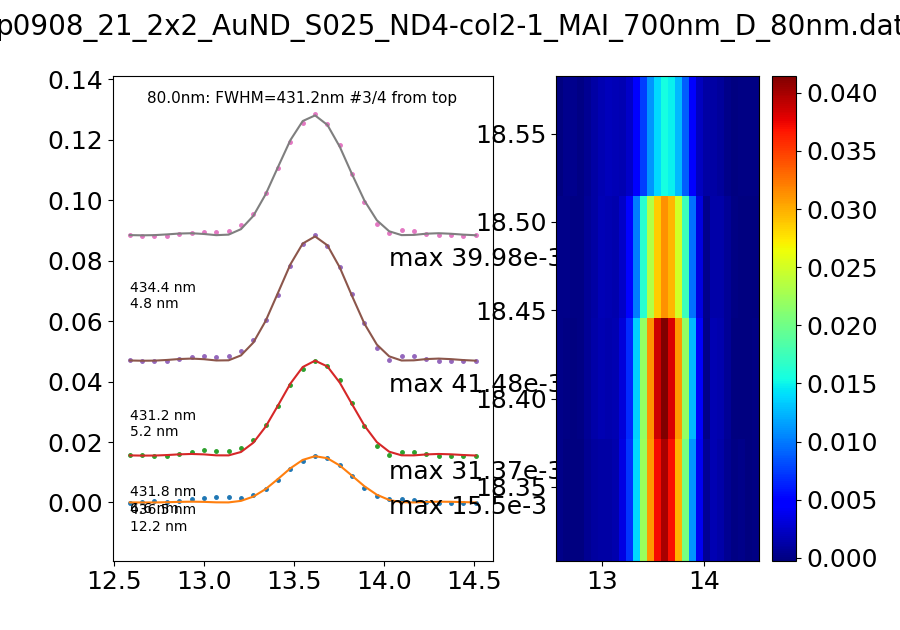

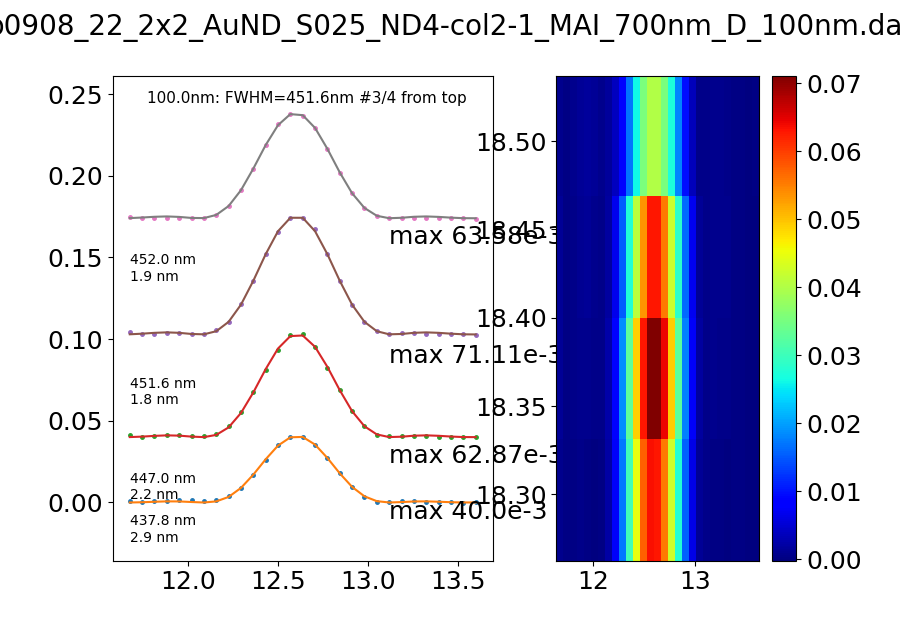

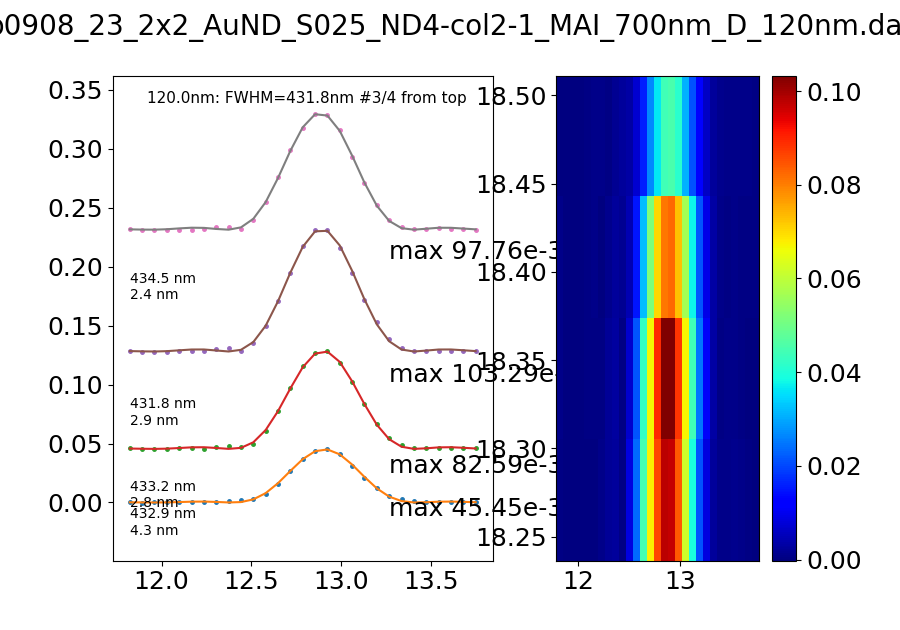

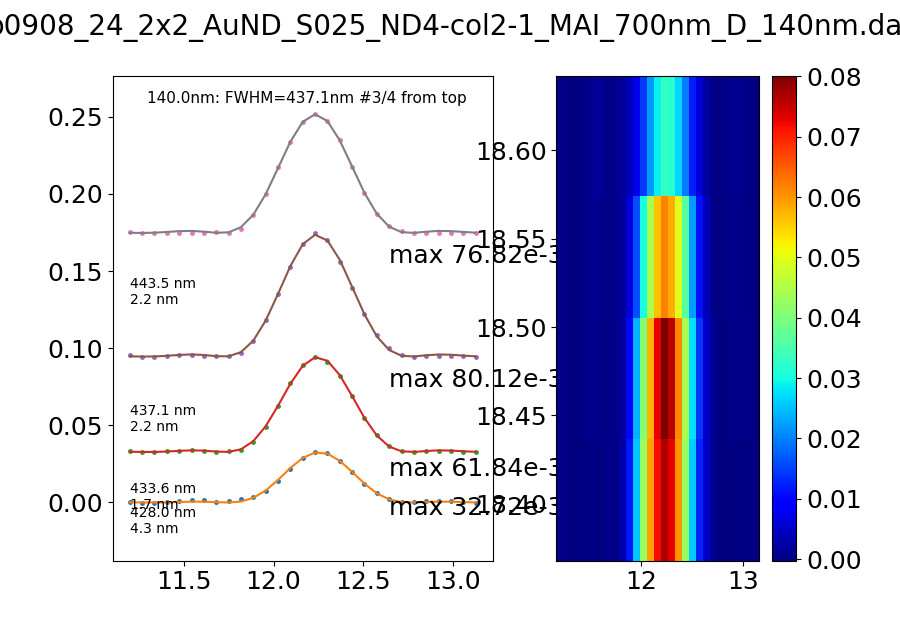

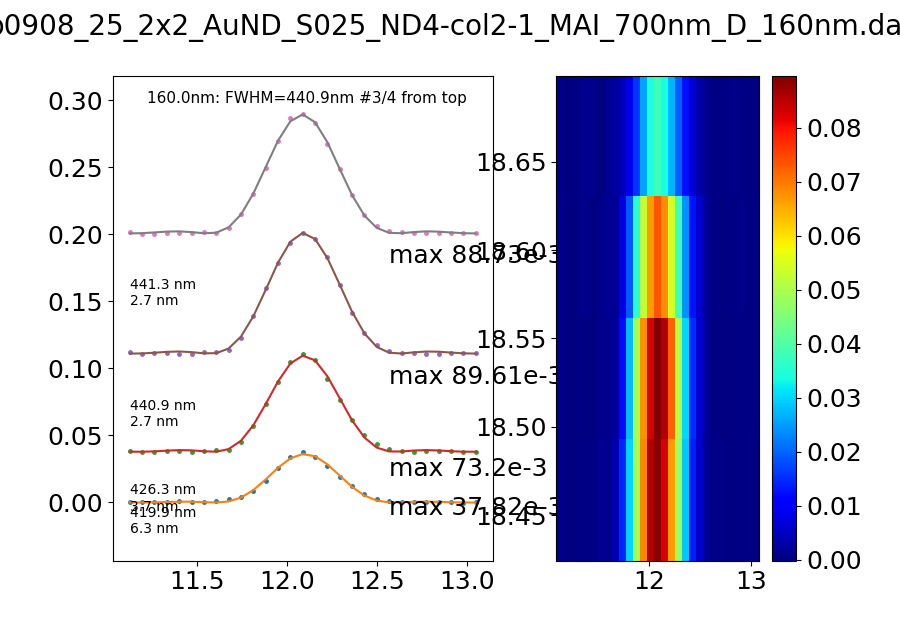

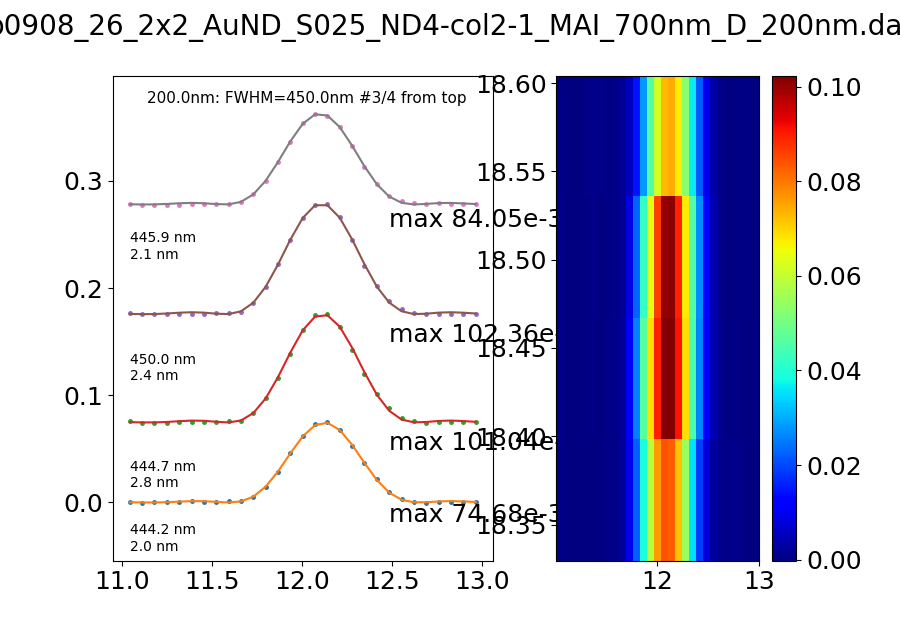

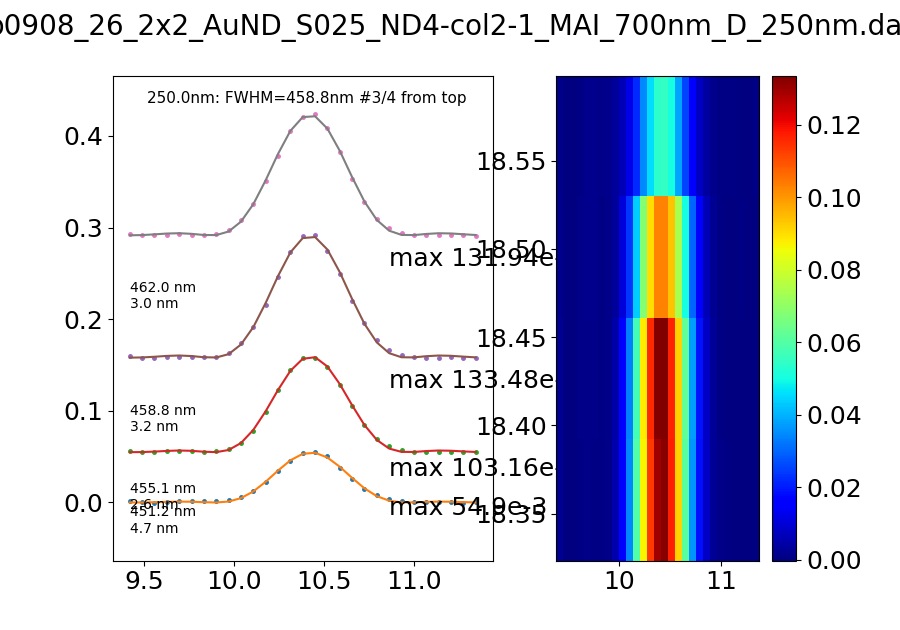

In [66]:
if check_fits :

    for key in Data :
        sms = Data[key]
        fig, (ax1, ax2) = plt.subplots(ncols=2,gridspec_kw = {'width_ratios':[3, 2]},figsize=(9,9/10.0*7))  #adapt fig height with number of linecuts
        p = ax2.pcolor(sms.x_cropped, sms.y_cropped, sms.DTT_cropped, cmap='jet')
        cb = fig.colorbar(p)

        plot_offset=0

        n_lines = np.size(sms.y_cropped)
        for line_index in range(n_lines) :

            line_DTT = sms.DTT_cropped[line_index,:]
            fig.suptitle(sms.fname, fontsize=fontsize/1.5)
            ax1.plot(sms.x_cropped,line_DTT+plot_offset,'.',markersize=5)
            ax1.plot(sms.x_cropped,line_fit(sms.x_cropped,*sms.all_vals[line_index])+plot_offset,'-',linewidth=1.5)
            ax1.text(sms.xmin,plot_offset-0.6*np.max(line_DTT), str(round(sms.all_best_wid[line_index],1)) + ' nm \n' + str(round(sms.all_std_wid[line_index],1)) + ' nm', size=10)
            ax1.text(sms.xmin+.75*(sms.xmax-sms.xmin),plot_offset-0.25*np.max(line_DTT), 'max ' + str(round(1e3*np.max(line_DTT),2))+'e-3')
            plot_offset = plot_offset + np.max(line_DTT) # implement offset
        
        ax1.text(sms.xmin+.05*(sms.xmax-sms.xmin),1.03*plot_offset, '{}nm: FWHM={:.1f}nm '.format(sms.wl,sms.FWHM_1D) + '#' + str(1+np.argmax(sms.all_best_amp)) + '/' + str(n_lines) + ' from top',fontsize=11)
        ax1.set_ylim([-0.15*plot_offset,1.1*plot_offset])

### 2D fits

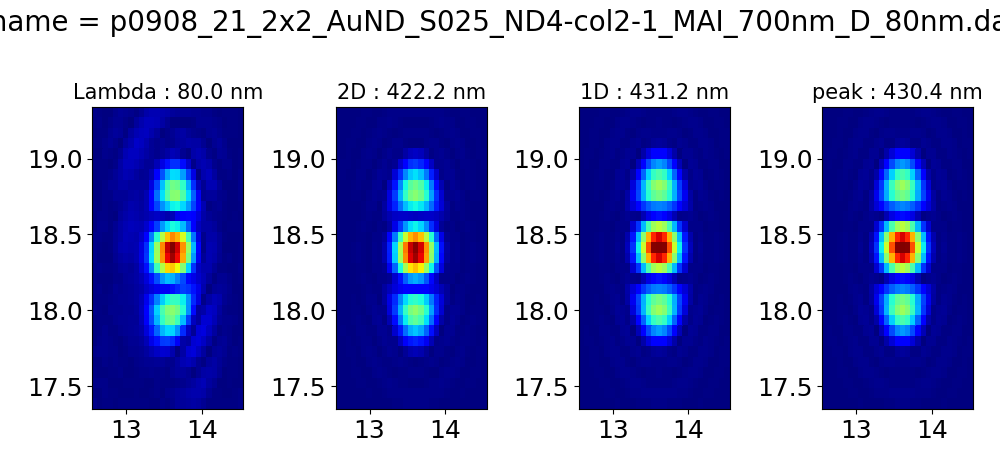

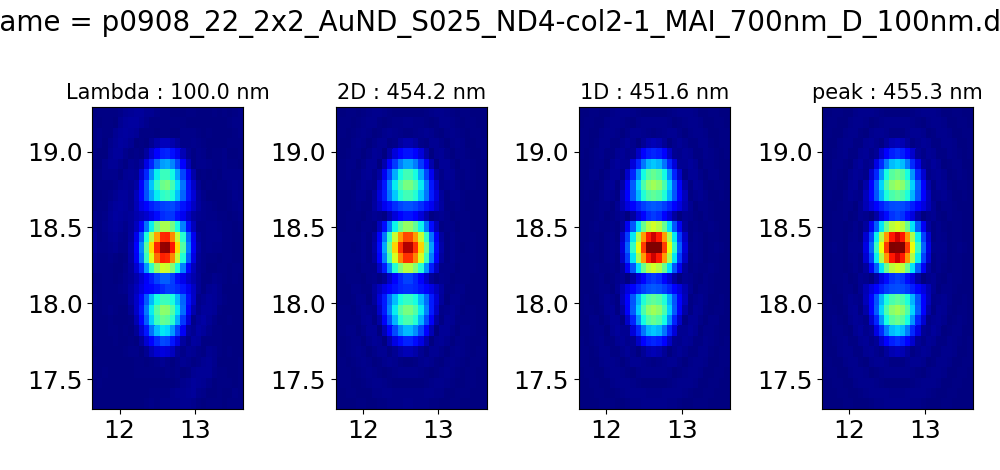

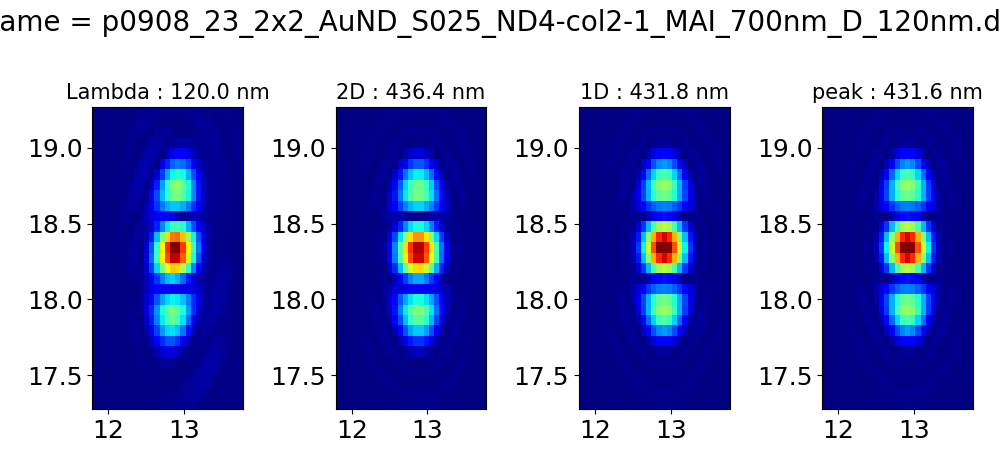

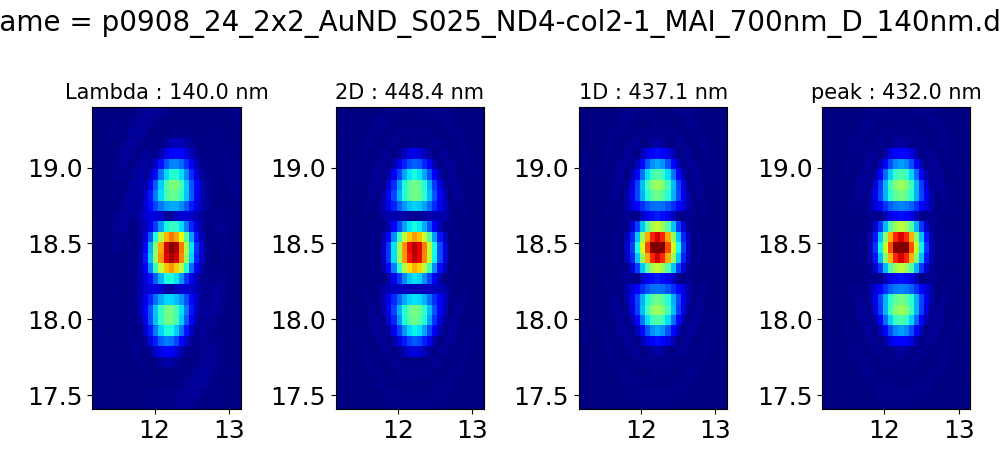

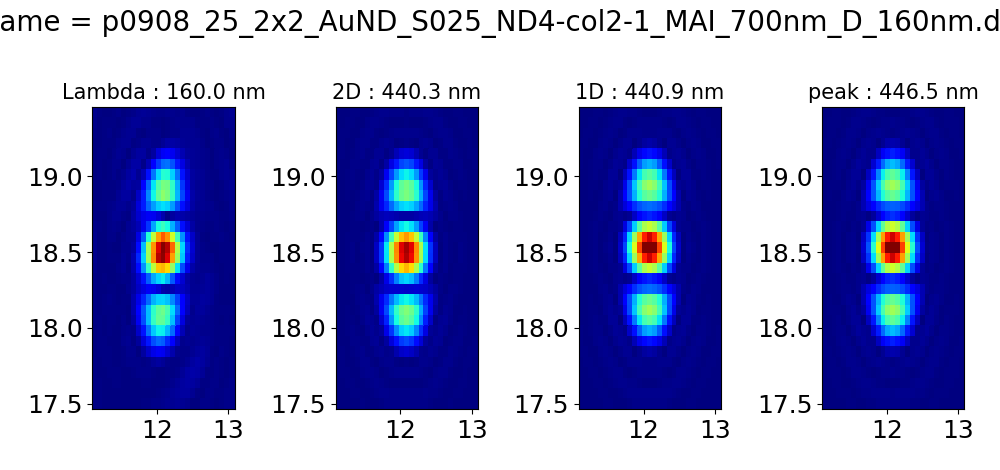

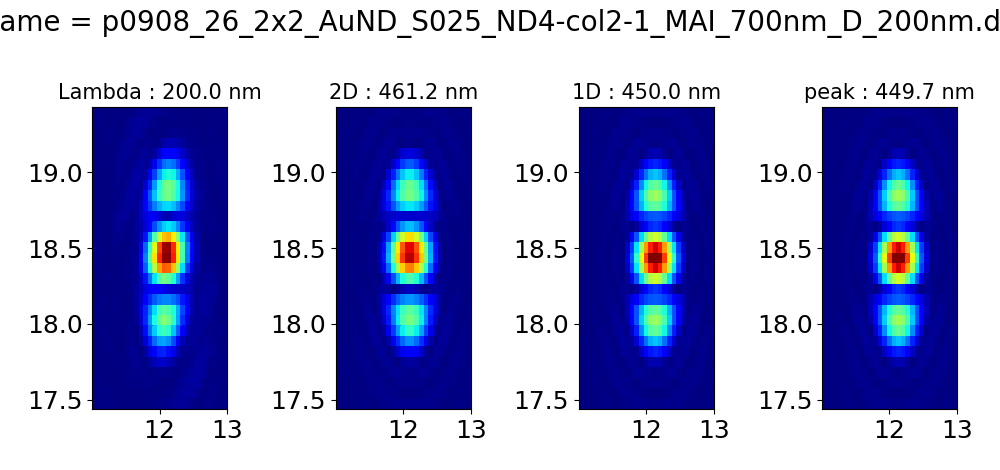

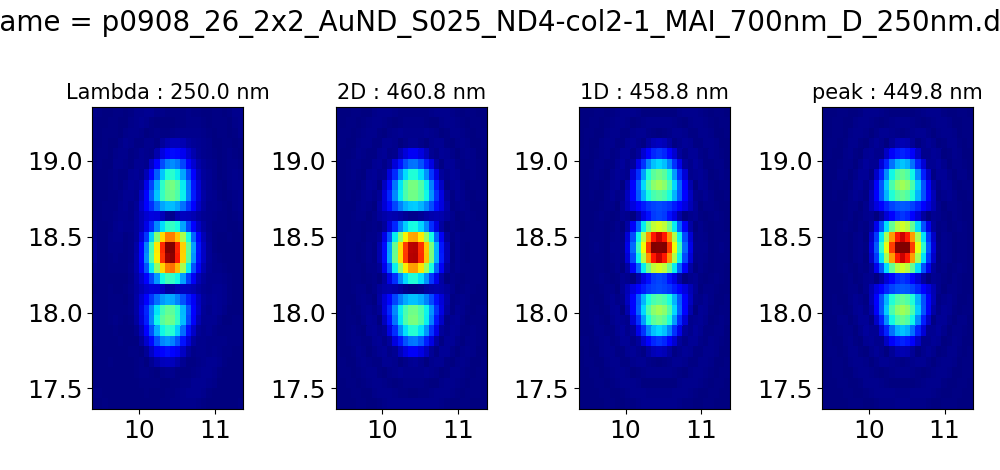

In [67]:
if check_fits :

    for key in Data :
        
        sms = Data[key]
        X, Y =np.meshgrid(sms.x, sms.y)
        DTT_fitted = DTT_fit((X,Y),**sms.fit_2D_vals)
        DTT_1D = abs(DTT(X, Y, xc = sms.init_vals_dict["x0"], yc = sms.init_vals_dict["y0"], amp = sms.amp_1D, d_y = sms.init_vals_dict["dy"], fwhm=sms.FWHM_1D*1e-3))
        DTT_1D = sms.amp_1D*DTT_1D/DTT_1D.max()

        DTT_peak = abs(DTT(X, Y, xc = sms.init_vals_dict["x0"], yc = sms.init_vals_dict["y0"], amp = sms.amp_1D, d_y = sms.init_vals_dict["dy"], fwhm=sms.FWHM_peak*1e-3))
        DTT_peak = sms.amp_1D*DTT_peak/DTT_peak.max()

        fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols=4, gridspec_kw = {'width_ratios':[1, 1, 1, 1]}, figsize=(10,4.7))
        vmax = max(sms.amp_1D,sms.amp_2D)

        plt.suptitle('fname = {}'.format(sms.fname), fontsize=fontsize/1.5)

        ax1.pcolor(sms.x, sms.y, sms.DTT,cmap='jet', vmax=vmax)
        title =  [param+ ' : {:.3f}'.format(sms.init_vals_dict[param]) for param in par_lists]
        #ax1.title.set_text(', '.join(title))
        ax1.set_title('Lambda : {:.1f} nm'.format(sms.wl), fontsize=15)

        ax2.pcolor(sms.x, sms.y, DTT_fitted.reshape(sms.ynumber,sms.xnumber), cmap='jet', vmax=vmax)
        title = [param+ ' : {:.3f} '.format(sms.fit_2D_vals[param]) for param in sms.fit_2D_vals]
        #ax2.title.set_text(', '.join(title))
        ax2.set_title('2D : {:.1f} nm'.format(sms.FWHM_2D), fontsize=15)

        ax3.pcolor(sms.x, sms.y, DTT_1D, cmap='jet', vmax = vmax )
        ax3.set_title('1D : {:.1f} nm'.format(sms.FWHM_1D), fontsize=15)

        ax4.pcolor(sms.x, sms.y, DTT_peak, cmap='jet', vmax = vmax )
        ax4.set_title('peak : {:.1f} nm'.format(sms.FWHM_peak), fontsize=15)

        plt.tight_layout()